In [ ]:
#@title
from __future__ import annotations

from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from typing import Sequence

import numpy as np
from numpy.typing import ArrayLike, NDArray


Vector = NDArray[np.float64]


class EvaluationBudgetExceeded(RuntimeError):
    """Raised before an objective evaluation would exceed the budget."""


@dataclass(frozen=True)
class Evaluation:
    n_eval: int
    x: Vector
    value: float
    best_x: Vector
    best_value: float


@dataclass
class RunResult:
    optimiser: str
    problem: str
    x_best: Vector
    f_best: float
    n_objective_evals: int
    n_gradient_evals: int
    n_hessian_evals: int
    evaluations: list[Evaluation]
    trajectory: list[Vector]
    success: bool
    message: str = ""

    @property
    def eval_numbers(self) -> NDArray[np.int_]:
        return np.asarray([item.n_eval for item in self.evaluations])

    @property
    def best_values(self) -> Vector:
        """Best objective found so far after each objective evaluation."""
        return np.asarray([item.best_value for item in self.evaluations])


class Problem(ABC):
    """Base class providing a simple API and automatic evaluation tracking.

    ``true_minima`` stores every known global minimiser, allowing plotting code
    to distinguish the known solution from the best point found by an optimiser.
    """

    def __init__(
        self,
        name: str,
        bounds: Sequence[tuple[float, float]],
        x0: ArrayLike,
        true_minima: Sequence[ArrayLike] = (),
    ) -> None:
        self.name = name
        self.bounds = tuple((float(lo), float(hi)) for lo, hi in bounds)
        self.x0 = np.asarray(x0, dtype=float)
        self.true_minima = tuple(
            np.asarray(x, dtype=float) for x in true_minima
        )

        if self.x0.shape != (len(self.bounds),):
            raise ValueError("x0 must have one entry per bound")

        if any(x.shape != self.x0.shape for x in self.true_minima):
            raise ValueError(
                "each true minimum must have one entry per bound"
            )

        self.reset()

    @property
    def dimension(self) -> int:
        return len(self.bounds)

    def reset(self, max_objective_evals: int | None = None) -> None:
        self.max_objective_evals = max_objective_evals
        self.n_objective_evals = 0
        self.n_gradient_evals = 0
        self.n_hessian_evals = 0
        self.evaluations: list[Evaluation] = []
        self.best_x: Vector | None = None
        self.best_value = np.inf

    def __call__(self, x: ArrayLike) -> float:
        """Evaluate and record the objective: ``problem(x)``."""
        if (
            self.max_objective_evals is not None
            and self.n_objective_evals >= self.max_objective_evals
        ):
            raise EvaluationBudgetExceeded

        x = self._validate_x(x)
        value = float(self.objective(x))

        self.n_objective_evals += 1

        if value < self.best_value:
            self.best_value = value
            self.best_x = x.copy()

        assert self.best_x is not None

        self.evaluations.append(
            Evaluation(
                n_eval=self.n_objective_evals,
                x=x.copy(),
                value=value,
                best_x=self.best_x.copy(),
                best_value=self.best_value,
            )
        )

        return value

    def grad(self, x: ArrayLike) -> Vector:
        self.n_gradient_evals += 1
        return np.asarray(
            self.gradient(self._validate_x(x)),
            dtype=float,
        )

    def hessian(self, x: ArrayLike) -> NDArray[np.float64]:
        self.n_hessian_evals += 1
        return np.asarray(
            self.hess(self._validate_x(x)),
            dtype=float,
        )

    def evaluate(self, x: ArrayLike) -> float:
        """Untracked evaluation, useful when drawing the objective landscape."""
        return float(self.objective(self._validate_x(x)))

    def _validate_x(self, x: ArrayLike) -> Vector:
        x = np.asarray(x, dtype=float)

        if x.shape != (self.dimension,):
            raise ValueError(
                f"expected shape ({self.dimension},), got {x.shape}"
            )

        return x

    @abstractmethod
    def objective(self, x: Vector) -> float:
        ...

    def gradient(self, x: Vector) -> Vector:
        raise NotImplementedError(
            f"{self.name} does not provide a gradient"
        )

    def hess(self, x: Vector) -> NDArray[np.float64]:
        raise NotImplementedError(
            f"{self.name} does not provide a Hessian"
        )

    def plot_contours(
        self,
        *,
        ax=None,
        resolution: int = 200,
        levels: int = 30,
        scale: str = "log",
        cmap: str = "inferno",
        contour_lines: bool = True,
        colorbar: bool = True,
        show_true_minima: bool = True,
    ):
        """Plot this objective when the problem is two-dimensional.

        Grid evaluations are untracked, so plotting does not consume
        the optimiser's objective-evaluation budget.

        Returns
        -------
        fig, ax, contour
        """
        import matplotlib.pyplot as plt

        if self.dimension != 2:
            raise ValueError(
                "Contour plots require a two-dimensional problem"
            )

        if resolution < 2 or levels < 2:
            raise ValueError(
                "resolution and levels must both be at least 2"
            )

        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 5))
        else:
            fig = ax.figure

        (x1_min, x1_max), (x2_min, x2_max) = self.bounds

        x1 = np.linspace(x1_min, x1_max, resolution)
        x2 = np.linspace(x2_min, x2_max, resolution)
        X1, X2 = np.meshgrid(x1, x2)

        Z = np.empty_like(X1)

        for index in np.ndindex(X1.shape):
            Z[index] = self.evaluate(
                [X1[index], X2[index]]
            )

        shifted = Z - np.nanmin(Z)

        if scale == "linear":
            display_Z = Z

        elif scale == "log":
            positive = shifted[shifted > 0]

            reference = (
                np.nanpercentile(positive, 5)
                if positive.size
                else 1.0
            )

            reference = max(
                reference,
                np.finfo(float).eps,
            )

            display_Z = np.log1p(
                shifted / reference
            )

        elif scale == "sqrt":
            display_Z = np.sqrt(shifted)

        else:
            raise ValueError(
                "scale must be 'linear', 'log', or 'sqrt'"
            )

        contour_levels = np.linspace(
            np.nanmin(display_Z),
            np.nanmax(display_Z),
            levels,
        )

        contour = ax.contourf(
            X1,
            X2,
            display_Z,
            levels=contour_levels,
            cmap=cmap,
        )

        if contour_lines:
            ax.contour(
                X1,
                X2,
                display_Z,
                levels=contour_levels[::3],
                colors="black",
                linewidths=0.4,
                alpha=0.5,
            )

        if show_true_minima and self.true_minima:
            minima = np.asarray(self.true_minima)

            ax.scatter(
                minima[:, 0],
                minima[:, 1],
                marker="X",
                s=70,
                facecolor="cyan",
                edgecolor="black",
                label="True minimum",
                zorder=5,
            )

        if colorbar:
            fig.colorbar(
                contour,
                ax=ax,
                label=f"Objective ({scale} display scale)",
            )

        ax.set(
            xlim=self.bounds[0],
            ylim=self.bounds[1],
            xlabel=r"$x_1$",
            ylabel=r"$x_2$",
            title=self.name,
        )

        return fig, ax, contour


class Quadratic(Problem):
    def __init__(self, condition: float = 100.0) -> None:
        self.A = np.diag([1.0, float(condition)])

        super().__init__(
            name="Quadratic",
            bounds=[(-3, 3), (-3, 3)],
            x0=[2, 2],
            true_minima=[[0, 0]],
        )

    def objective(self, x: Vector) -> float:
        return float(0.5 * x @ self.A @ x)

    def gradient(self, x: Vector) -> Vector:
        return self.A @ x

    def hess(self, x: Vector) -> NDArray[np.float64]:
        return self.A.copy()


class Rosenbrock(Problem):
    def __init__(self) -> None:
        super().__init__(
            name="Rosenbrock",
            bounds=[(-2, 2), (-1, 3)],
            x0=[-1.5, 2.0],
            true_minima=[[1, 1]],
        )

    def objective(self, x: Vector) -> float:
        return float(
            (1 - x[0]) ** 2
            + 100 * (x[1] - x[0] ** 2) ** 2
        )

    def gradient(self, x: Vector) -> Vector:
        return np.array(
            [
                2 * (x[0] - 1)
                - 400 * x[0] * (x[1] - x[0] ** 2),
                200 * (x[1] - x[0] ** 2),
            ]
        )

    def hess(self, x: Vector) -> NDArray[np.float64]:
        return np.array(
            [
                [
                    1200 * x[0] ** 2 - 400 * x[1] + 2,
                    -400 * x[0],
                ],
                [
                    -400 * x[0],
                    200,
                ],
            ]
        )


class Himmelblau(Problem):
    def __init__(self) -> None:
        super().__init__(
            name="Himmelblau",
            bounds=[(-5, 5), (-5, 5)],
            x0=[0, 0],
            true_minima=[
                [3.0, 2.0],
                [-2.805118, 3.131312],
                [-3.779310, -3.283186],
                [3.584428, -1.848126],
            ],
        )

    def objective(self, x: Vector) -> float:
        a = x[0] ** 2 + x[1] - 11
        b = x[0] + x[1] ** 2 - 7

        return float(a * a + b * b)

    def gradient(self, x: Vector) -> Vector:
        a = x[0] ** 2 + x[1] - 11
        b = x[0] + x[1] ** 2 - 7

        return np.array(
            [
                4 * x[0] * a + 2 * b,
                2 * a + 4 * x[1] * b,
            ]
        )

    def hess(self, x: Vector) -> NDArray[np.float64]:
        return np.array(
            [
                [
                    12 * x[0] ** 2 + 4 * x[1] - 42,
                    4 * (x[0] + x[1]),
                ],
                [
                    4 * (x[0] + x[1]),
                    4 * x[0] + 12 * x[1] ** 2 - 26,
                ],
            ]
        )


class Rastrigin(Problem):
    def __init__(self, dimension: int = 2) -> None:
        bounds = [(-5.12, 5.12)] * dimension

        super().__init__(
            name="Rastrigin",
            bounds=bounds,
            x0=[3.5] * dimension,
            true_minima=[[0.0] * dimension],
        )

    def objective(self, x: Vector) -> float:
        return float(
            10 * self.dimension
            + np.sum(
                x * x - 10 * np.cos(2 * np.pi * x)
            )
        )

    def gradient(self, x: Vector) -> Vector:
        return (
            2 * x
            + 20 * np.pi * np.sin(2 * np.pi * x)
        )

    def hess(self, x: Vector) -> NDArray[np.float64]:
        diagonal = (
            2
            + 40 * np.pi**2 * np.cos(2 * np.pi * x)
        )

        return np.diag(diagonal)


class Optimiser(ABC):
    @abstractmethod
    def run(
        self,
        problem: Problem,
        x0: ArrayLike | None = None,
        max_evals: int = 500,
        seed: int = 0,
    ) -> RunResult:
        ...

    def _start(
        self,
        problem: Problem,
        x0: ArrayLike | None,
        max_evals: int,
    ) -> Vector:
        problem.reset(max_evals)

        return problem._validate_x(
            problem.x0 if x0 is None else x0
        ).copy()

    def _result(
        self,
        problem: Problem,
        trajectory: list[Vector],
        success: bool,
        message: str,
    ) -> RunResult:
        if problem.best_x is None:
            raise RuntimeError(
                "optimiser made no objective evaluations"
            )

        return RunResult(
            optimiser=type(self).__name__,
            problem=problem.name,
            x_best=problem.best_x.copy(),
            f_best=problem.best_value,
            n_objective_evals=problem.n_objective_evals,
            n_gradient_evals=problem.n_gradient_evals,
            n_hessian_evals=problem.n_hessian_evals,
            evaluations=list(problem.evaluations),
            trajectory=[x.copy() for x in trajectory],
            success=success,
            message=message,
        )


# ---------------------------------------------------------------------
# Global optimisers
# ---------------------------------------------------------------------


@dataclass
class RandomSearch(Optimiser):
    """Uniform random search within the problem bounds."""

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        self._start(
            problem,
            x0,
            max_evals,
        )

        rng = np.random.default_rng(seed)
        lower, upper = np.asarray(
            problem.bounds
        ).T

        trajectory = []

        while (
            problem.n_objective_evals
            < max_evals
        ):
            x = rng.uniform(
                lower,
                upper,
            )

            problem(x)

            # Record every evaluated location. Best-so-far
            # values are stored separately in evaluations.
            trajectory.append(problem.best_x.copy())

        return self._result(
            problem,
            trajectory,
            True,
            "evaluation budget reached",
        )


@dataclass
class SimulatedAnnealing(Optimiser):
    """Bounded simulated annealing with Gaussian proposals."""

    initial_temperature: float = 10.0
    cooling_rate: float = 0.98
    step_scale: float = 0.15
    minimum_temperature: float = 1e-8

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        x = self._start(
            problem,
            x0,
            max_evals,
        )

        rng = np.random.default_rng(seed)

        lower, upper = np.asarray(
            problem.bounds
        ).T

        widths = upper - lower

        value = problem(x)
        trajectory = [x.copy()]

        temperature = self.initial_temperature

        while (
            problem.n_objective_evals
            < max_evals
        ):
            proposal = (
                x
                + rng.normal(size=problem.dimension)
                * self.step_scale
                * widths
            )

            proposal = np.clip(
                proposal,
                lower,
                upper,
            )

            proposal_value = problem(proposal)
            difference = proposal_value - value

            accept = (
                difference <= 0
                or rng.random()
                < np.exp(
                    -difference
                    / max(temperature, 1e-300)
                )
            )

            if accept:
                x = proposal
                value = proposal_value
                trajectory.append(problem.best_x.copy())

            temperature = max(
                self.minimum_temperature,
                temperature * self.cooling_rate,
            )

        return self._result(
            problem,
            trajectory,
            True,
            "evaluation budget reached",
        )


@dataclass
class DifferentialEvolution(Optimiser):
    """Bounded differential evolution using DE/rand/1/bin."""

    population_size: int = 20
    mutation: float = 0.8
    crossover: float = 0.7

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        self._start(
            problem,
            x0,
            max_evals,
        )

        if self.population_size < 4:
            raise ValueError(
                "population_size must be at least 4"
            )

        rng = np.random.default_rng(seed)

        lower, upper = np.asarray(
            problem.bounds
        ).T

        population_size = min(
            self.population_size,
            max_evals,
        )

        population = rng.uniform(
            lower,
            upper,
            size=(
                population_size,
                problem.dimension,
            ),
        )

        values = np.array(
            [problem(x) for x in population]
        )

        best_index = np.argmin(values)

        trajectory = [
            population[best_index].copy()
        ]

        while (
            problem.n_objective_evals
            < max_evals
        ):
            for index in range(population_size):
                if (
                    problem.n_objective_evals
                    >= max_evals
                ):
                    break

                candidates = np.delete(
                    np.arange(population_size),
                    index,
                )

                if len(candidates) < 3:
                    break

                first, second, third = rng.choice(
                    candidates,
                    size=3,
                    replace=False,
                )

                mutant = (
                    population[first]
                    + self.mutation
                    * (
                        population[second]
                        - population[third]
                    )
                )

                mutant = np.clip(
                    mutant,
                    lower,
                    upper,
                )

                crossover_mask = (
                    rng.random(problem.dimension)
                    < self.crossover
                )

                # Ensure at least one mutant component is used.
                forced_index = rng.integers(
                    problem.dimension
                )
                crossover_mask[forced_index] = True

                trial = np.where(
                    crossover_mask,
                    mutant,
                    population[index],
                )

                trial_value = problem(trial)

                if trial_value <= values[index]:
                    population[index] = trial
                    values[index] = trial_value

            best_index = np.argmin(values)

            trajectory.append(
                population[best_index].copy()
            )

        return self._result(
            problem,
            trajectory,
            True,
            "evaluation budget reached",
        )

@dataclass
class BayesianOptimisation(Optimiser):
    """Gaussian-process Bayesian optimisation with expected improvement."""

    n_initial: int = 5
    n_candidates: int = 2000
    length_scale: float = 0.4
    noise: float = 1e-8
    exploration: float = 0.01

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        from scipy.special import ndtr

        if (
            max_evals < 1
            or self.n_initial < 1
            or self.n_candidates < 1
        ):
            raise ValueError(
                "budgets and sample counts must be positive"
            )

        if self.length_scale <= 0:
            raise ValueError(
                "length_scale must be positive"
            )

        start = self._start(
            problem,
            x0,
            max_evals,
        )

        rng = np.random.default_rng(seed)
        lows, highs = np.asarray(problem.bounds).T
        widths = highs - lows

        points: list[Vector] = []
        values: list[float] = []
        trajectory: list[Vector] = []

        # Start with x0, followed by uniformly sampled points.
        initial_points = [start]

        initial_points.extend(
            rng.uniform(lows, highs)
            for _ in range(
                min(self.n_initial, max_evals) - 1
            )
        )

        for point in initial_points:
            points.append(point.copy())
            values.append(problem(point))
            trajectory.append(point.copy())

        def rbf(
            first: np.ndarray,
            second: np.ndarray,
        ) -> np.ndarray:
            squared_distance = np.sum(
                (
                    first[:, None, :]
                    - second[None, :, :]
                )
                ** 2,
                axis=2,
            )

            return np.exp(
                -0.5
                * squared_distance
                / self.length_scale**2
            )

        while problem.n_objective_evals < max_evals:
            # Normalise inputs to the unit hypercube.
            train_x = (
                np.asarray(points) - lows
            ) / widths

            train_y = np.asarray(values)

            # Standardise objective values.
            y_scale = max(
                train_y.std(),
                1e-12,
            )

            standard_y = (
                train_y - train_y.mean()
            ) / y_scale

            # Fit the Gaussian process.
            covariance = rbf(
                train_x,
                train_x,
            )

            covariance.flat[
                :: len(train_x) + 1
            ] += self.noise

            cholesky = np.linalg.cholesky(
                covariance
            )

            alpha = np.linalg.solve(
                cholesky.T,
                np.linalg.solve(
                    cholesky,
                    standard_y,
                ),
            )

            # Candidate locations for acquisition
            # maximisation.
            candidates = rng.uniform(
                0.0,
                1.0,
                size=(
                    self.n_candidates,
                    problem.dimension,
                ),
            )

            cross_covariance = rbf(
                train_x,
                candidates,
            )

            mean = cross_covariance.T @ alpha

            solved = np.linalg.solve(
                cholesky,
                cross_covariance,
            )

            variance = np.maximum(
                1.0 - np.sum(
                    solved**2,
                    axis=0,
                ),
                0.0,
            )

            standard_deviation = np.sqrt(
                variance
            )

            # Expected improvement for minimisation.
            improvement = (
                standard_y.min()
                - mean
                - self.exploration
            )

            z = np.divide(
                improvement,
                standard_deviation,
                out=np.zeros_like(improvement),
                where=standard_deviation > 0,
            )

            density = (
                np.exp(-0.5 * z**2)
                / np.sqrt(2 * np.pi)
            )

            expected_improvement = (
                improvement * ndtr(z)
                + standard_deviation * density
            )

            expected_improvement[
                standard_deviation == 0
            ] = 0.0

            # Evaluate the candidate with maximum EI.
            next_unit = candidates[
                np.argmax(expected_improvement)
            ]

            next_point = (
                lows + widths * next_unit
            )

            points.append(next_point.copy())
            values.append(problem(next_point))
            trajectory.append(problem.best_x.copy())

        return self._result(
            problem,
            trajectory,
            True,
            "evaluation budget reached",
        )


@dataclass
class ParticleSwarm(Optimiser):
    """Bounded particle swarm with global-best communication."""

    swarm_size: int = 20
    inertia: float = 0.7
    cognitive: float = 1.5
    social: float = 1.5

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        self._start(
            problem,
            x0,
            max_evals,
        )

        rng = np.random.default_rng(seed)

        lower, upper = np.asarray(
            problem.bounds
        ).T

        swarm_size = min(
            self.swarm_size,
            max_evals,
        )

        positions = rng.uniform(
            lower,
            upper,
            size=(
                swarm_size,
                problem.dimension,
            ),
        )

        widths = upper - lower

        velocities = (
            rng.uniform(
                -widths,
                widths,
                size=positions.shape,
            )
            * 0.1
        )

        values = np.array(
            [problem(x) for x in positions]
        )

        personal_best = positions.copy()
        personal_best_values = values.copy()

        global_best_index = np.argmin(
            personal_best_values
        )

        global_best = personal_best[
            global_best_index
        ].copy()

        trajectory = [global_best.copy()]

        while (
            problem.n_objective_evals
            < max_evals
        ):
            random_cognitive = rng.random(
                positions.shape
            )
            random_social = rng.random(
                positions.shape
            )

            velocities = (
                self.inertia * velocities
                + self.cognitive
                * random_cognitive
                * (personal_best - positions)
                + self.social
                * random_social
                * (global_best - positions)
            )

            positions = np.clip(
                positions + velocities,
                lower,
                upper,
            )

            for index in range(swarm_size):
                if (
                    problem.n_objective_evals
                    >= max_evals
                ):
                    break

                value = problem(
                    positions[index]
                )

                if (
                    value
                    < personal_best_values[index]
                ):
                    personal_best[index] = (
                        positions[index].copy()
                    )
                    personal_best_values[index] = (
                        value
                    )

            global_best_index = np.argmin(
                personal_best_values
            )

            global_best = personal_best[
                global_best_index
            ].copy()

            trajectory.append(
                global_best.copy()
            )

        return self._result(
            problem,
            trajectory,
            True,
            "evaluation budget reached",
        )


# ---------------------------------------------------------------------
# Local optimisers
# ---------------------------------------------------------------------


@dataclass
class GradientDescent(Optimiser):
    learning_rate: float = 1e-3
    tolerance: float = 1e-8

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        x = self._start(
            problem,
            x0,
            max_evals,
        )

        trajectory = [x.copy()]

        success = False
        message = "evaluation budget reached"

        try:
            while True:
                problem(x)
                gradient = problem.grad(x)

                if (
                    np.linalg.norm(gradient)
                    <= self.tolerance
                ):
                    success = True
                    message = (
                        "gradient tolerance reached"
                    )
                    break

                x = (
                    x
                    - self.learning_rate
                    * gradient
                )

                trajectory.append(x.copy())

        except EvaluationBudgetExceeded:
            pass

        return self._result(
            problem,
            trajectory,
            success,
            message,
        )


@dataclass
class Momentum(Optimiser):
    learning_rate: float = 1e-3
    momentum: float = 0.9
    tolerance: float = 1e-8

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        x = self._start(
            problem,
            x0,
            max_evals,
        )

        velocity = np.zeros_like(x)
        trajectory = [x.copy()]

        success = False
        message = "evaluation budget reached"

        try:
            while True:
                problem(x)
                gradient = problem.grad(x)

                if (
                    np.linalg.norm(gradient)
                    <= self.tolerance
                ):
                    success = True
                    message = (
                        "gradient tolerance reached"
                    )
                    break

                velocity = (
                    self.momentum * velocity
                    - self.learning_rate
                    * gradient
                )

                x = x + velocity
                trajectory.append(x.copy())

        except EvaluationBudgetExceeded:
            pass

        return self._result(
            problem,
            trajectory,
            success,
            message,
        )


@dataclass
class Adam(Optimiser):
    learning_rate: float = 0.03
    beta1: float = 0.9
    beta2: float = 0.999
    epsilon: float = 1e-8
    tolerance: float = 1e-8

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        x = self._start(
            problem,
            x0,
            max_evals,
        )

        first_moment = np.zeros_like(x)
        second_moment = np.zeros_like(x)

        trajectory = [x.copy()]

        success = False
        message = "evaluation budget reached"
        iteration = 0

        try:
            while True:
                problem(x)
                gradient = problem.grad(x)

                if (
                    np.linalg.norm(gradient)
                    <= self.tolerance
                ):
                    success = True
                    message = (
                        "gradient tolerance reached"
                    )
                    break

                iteration += 1

                first_moment = (
                    self.beta1 * first_moment
                    + (1 - self.beta1)
                    * gradient
                )

                second_moment = (
                    self.beta2 * second_moment
                    + (1 - self.beta2)
                    * gradient**2
                )

                corrected_first = (
                    first_moment
                    / (1 - self.beta1**iteration)
                )

                corrected_second = (
                    second_moment
                    / (1 - self.beta2**iteration)
                )

                x = (
                    x
                    - self.learning_rate
                    * corrected_first
                    / (
                        np.sqrt(corrected_second)
                        + self.epsilon
                    )
                )

                trajectory.append(x.copy())

        except EvaluationBudgetExceeded:
            pass

        return self._result(
            problem,
            trajectory,
            success,
            message,
        )


@dataclass
class Newton(Optimiser):
    tolerance: float = 1e-8
    damping: float = 1.0

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        x = self._start(
            problem,
            x0,
            max_evals,
        )

        trajectory = [x.copy()]

        success = False
        message = "evaluation budget reached"

        try:
            while True:
                problem(x)
                gradient = problem.grad(x)

                if (
                    np.linalg.norm(gradient)
                    <= self.tolerance
                ):
                    success = True
                    message = (
                        "gradient tolerance reached"
                    )
                    break

                step = np.linalg.solve(
                    problem.hessian(x),
                    gradient,
                )

                x = (
                    x
                    - self.damping * step
                )

                trajectory.append(x.copy())

        except EvaluationBudgetExceeded:
            pass

        except np.linalg.LinAlgError:
            message = "singular Hessian"

        return self._result(
            problem,
            trajectory,
            success,
            message,
        )


@dataclass
class ScipyMinimise(Optimiser):
    """Adapter for SciPy local optimisation methods."""

    method: str = "Nelder-Mead"
    use_gradient: bool = False
    options: dict = field(default_factory=dict)

    def run(
        self,
        problem: Problem,
        x0=None,
        max_evals=500,
        seed=0,
    ) -> RunResult:
        from scipy.optimize import minimize

        x = self._start(
            problem,
            x0,
            max_evals,
        )

        trajectory = [x.copy()]

        def callback(xk: Vector) -> None:
            trajectory.append(
                np.asarray(
                    xk,
                    dtype=float,
                ).copy()
            )

        try:
            if self.method.lower() in {
                "nelder-mead",
                "powell",
            }:
                budget_option = {
                    "maxfev": max_evals
                }
            else:
                budget_option = {
                    "maxiter": max_evals
                }

            result = minimize(
                problem,
                x,
                jac=(
                    problem.grad
                    if self.use_gradient
                    else None
                ),
                method=self.method,
                callback=callback,
                options={
                    **budget_option,
                    **self.options,
                },
            )

            success = bool(result.success)
            message = str(result.message)

        except EvaluationBudgetExceeded:
            success = False
            message = "evaluation budget reached"

        return self._result(
            problem,
            trajectory,
            success,
            message,
        )


def default_problems() -> dict[str, Problem]:
    problems = {
        "quadratic": Quadratic(),
        "rosenbrock": Rosenbrock(),
        "himmelblau": Himmelblau(),
        "rastrigin": Rastrigin(),
    }

    print(
        "Loaded default optimisation problems: "
        + ", ".join(problem.name for problem in problems.values())
    )

    return problems


def local_optimisers() -> dict[str, Optimiser]:
    """Local optimisers used in the default comparison matrix."""
    opts = {
        "nelder_mead": ScipyMinimise(
            "Nelder-Mead"
        ),
        "gradient_descent": GradientDescent(),
        "momentum": Momentum(),
        "adam": Adam(),
        "bfgs": ScipyMinimise(
            "BFGS",
            use_gradient=True,
        ),
        "newton": Newton(),
    }

    print(
        "Loaded local optimisers: "
        + ", ".join(
                    o
                    .replace("_", " ")
                    .title()
 for o in opts.keys())
    )
    return opts


def global_optimisers() -> dict[str, Optimiser]:
    """Global optimisers, separate from the default local methods."""
    opts = {
        "random_search": RandomSearch(),
        "simulated_annealing": (
            SimulatedAnnealing()
        ),
        "bayesian_optimisation": (
            BayesianOptimisation()
        ),
    }
    print(
        "Loaded global optimisers: "
        + ", ".join(
                    o
                    .replace("_", " ")
                    .title()
 for o in opts.keys())
    )
    return opts


In [ ]:
from collections.abc import Mapping

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.axes import Axes
from matplotlib.figure import Figure


Results = dict[tuple[str, str], RunResult]


def run_matrix(
    problems: Mapping[str, Problem],
    optimisers: Mapping[str, Optimiser],
    *,
    max_evals: int = 500,
    seed: int = 0,
) -> Results:
    """Run every optimiser on every problem using a common budget and seed."""
    return {
        (problem_key, optimiser_key): optimiser.run(
            problem,
            max_evals=max_evals,
            seed=seed,
        )
        for problem_key, problem in problems.items()
        for optimiser_key, optimiser in optimisers.items()
    }


def _axes_grid(
    axes: object,
    nrows: int,
    ncols: int,
) -> np.ndarray:
    """Always return axes as a two-dimensional array."""
    return np.asarray(
        axes,
        dtype=object,
    ).reshape(nrows, ncols)


def _objective_grid(
    problem: Problem,
    resolution: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    if problem.dimension != 2:
        raise ValueError(
            f"contour plots require a 2D problem; "
            f"{problem.name!r} has dimension "
            f"{problem.dimension}"
        )

    (x_min, x_max), (y_min, y_max) = problem.bounds

    x = np.linspace(x_min, x_max, resolution)
    y = np.linspace(y_min, y_max, resolution)

    X, Y = np.meshgrid(x, y)
    Z = np.empty_like(X)

    # problem.evaluate is deliberately untracked, so plotting does not
    # alter the optimisation evaluation counts.
    for index in np.ndindex(X.shape):
        Z[index] = problem.evaluate(
            [X[index], Y[index]]
        )

    return X, Y, Z


def _transform_contours(
    Z: np.ndarray,
    scale: str,
) -> np.ndarray:
    """Return a monotone display transform of an objective surface."""
    shifted = Z - np.nanmin(Z)

    if scale == "linear":
        return Z

    if scale == "log":
        # Base the scale on a small positive grid value so the transform
        # works for objectives with very different natural scales.
        positive = shifted[shifted > 0]

        if positive.size:
            reference = np.nanpercentile(positive, 5)
        else:
            reference = 1.0

        reference = max(
            reference,
            np.finfo(float).eps,
        )

        return np.log1p(shifted / reference)

    if scale == "sqrt":
        return np.sqrt(shifted)

    raise ValueError(
        "contour_scale must be "
        "'linear', 'log', or 'sqrt'"
    )


def plot_trajectory_matrix(
    problems: Mapping[str, Problem],
    optimisers: Mapping[str, Optimiser],
    results: Mapping[tuple[str, str], RunResult] | None = None,
    *,
    max_evals: int = 500,
    seed: int = 0,
    resolution: int = 180,
    levels: int = 35,
    cmap: str = "magma",
    contour_scale: str = "log",
    contour_lines: bool = True,
    show_true_minima: bool = True,
    figsize_per_cell: tuple[float, float] = (3.6, 3.3),
) -> tuple[Figure, np.ndarray, Results]:
    """Plot problem contours with each optimiser's trajectory overlaid.

    If ``results`` is omitted, the full experiment matrix is run first.

    Returns ``(figure, axes, results)`` so callers can further customise
    or save the figure.
    """
    if results is None:
        results = run_matrix(
            problems,
            optimisers,
            max_evals=max_evals,
            seed=seed,
        )

    results = dict(results)

    nrows = len(problems)
    ncols = len(optimisers)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            figsize_per_cell[0] * ncols,
            figsize_per_cell[1] * nrows,
        ),
        squeeze=False,
        constrained_layout=True,
    )

    axes = _axes_grid(
        axes,
        nrows,
        ncols,
    )

    for row, (problem_key, problem) in enumerate(
        problems.items()
    ):
        X, Y, Z = _objective_grid(
            problem,
            resolution,
        )

        display_Z = _transform_contours(
            Z,
            contour_scale,
        )

        contour_levels = np.linspace(
            np.nanmin(display_Z),
            np.nanmax(display_Z),
            levels,
        )

        for col, (optimiser_key, _) in enumerate(
            optimisers.items()
        ):
            ax: Axes = axes[row, col]

            result = results[
                (problem_key, optimiser_key)
            ]

            trajectory = np.asarray(
                result.trajectory,
                dtype=float,
            )

            ax.contourf(
                X,
                Y,
                display_Z,
                levels=contour_levels,
                cmap=cmap,
            )

            if contour_lines:
                ax.contour(
                    X,
                    Y,
                    display_Z,
                    levels=contour_levels[::3],
                    colors="black",
                    linewidths=0.35,
                    alpha=0.45,
                )

            if len(trajectory):
                ax.plot(
                    trajectory[:, 0],
                    trajectory[:, 1],
                    "-o",
                    color="white",
                    markeredgecolor="black",
                    markeredgewidth=0.25,
                    linewidth=1.2,
                    markersize=2.5,
                    alpha=0.9,
                    zorder=3,
                )

                ax.scatter(
                    *trajectory[0],
                    s=45,
                    facecolor="white",
                    edgecolor="black",
                    zorder=4,
                )

            # Best point found by the optimiser.
            ax.scatter(
                *result.x_best,
                marker="*",
                s=110,
                facecolor="red",
                edgecolor="black",
                linewidth=0.6,
                zorder=5,
            )

            # Known global minima.
            if show_true_minima and problem.true_minima:
                true_minima = np.asarray(
                    problem.true_minima
                )

                ax.scatter(
                    true_minima[:, 0],
                    true_minima[:, 1],
                    marker="X",
                    s=65,
                    facecolor="cyan",
                    edgecolor="black",
                    linewidth=0.7,
                    zorder=5,
                    label="True minimum",
                )

            if row == 0:
                ax.set_title(
                    optimiser_key
                    .replace("_", " ")
                    .title()
                )

            ax.text(
                0.02,
                0.02,
                (
                    f"best = {result.f_best:.2e}\n"
                    f"evals = "
                    f"{result.n_objective_evals}"
                ),
                transform=ax.transAxes,
                fontsize=8,
                color="white",
                va="bottom",
                bbox={
                    "facecolor": "black",
                    "alpha": 0.55,
                    "pad": 2,
                },
                zorder=6,
            )

            ax.set_xlim(problem.bounds[0])
            ax.set_ylim(problem.bounds[1])
            ax.set_aspect(
                "equal",
                adjustable="box",
            )
            ax.set_xlabel("$x_1$")

            if col == 0:
                ax.set_ylabel(
                    f"{problem.name}\n$x_2$"
                )

    return fig, axes, results


def plot_convergence_matrix(
    problems: Mapping[str, Problem],
    optimisers: Mapping[str, Optimiser],
    results: Mapping[tuple[str, str], RunResult],
    *,
    figsize_per_cell: tuple[float, float] = (3.6, 2.5),
) -> tuple[Figure, np.ndarray]:
    """Plot best objective found so far against objective evaluations."""
    nrows = len(problems)
    ncols = len(optimisers)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            figsize_per_cell[0] * ncols,
            figsize_per_cell[1] * nrows,
        ),
        squeeze=False,
        constrained_layout=True,
    )

    axes = _axes_grid(
        axes,
        nrows,
        ncols,
    )

    for row, (problem_key, problem) in enumerate(
        problems.items()
    ):
        for col, (optimiser_key, _) in enumerate(
            optimisers.items()
        ):
            ax: Axes = axes[row, col]

            result = results[
                (problem_key, optimiser_key)
            ]

            ax.step(
                result.eval_numbers,
                result.best_values,
                where="post",
            )

            ax.set_yscale(
                "symlog",
                linthresh=1e-10,
            )

            ax.grid(alpha=0.25)

            if row == 0:
                ax.set_title(
                    optimiser_key
                    .replace("_", " ")
                    .title()
                )

            if row == nrows - 1:
                ax.set_xlabel(
                    "Objective evaluations"
                )

            if col == 0:
                ax.set_ylabel(
                    f"{problem.name}\n"
                    "Best objective"
                )

    return fig, axes

def plot_result(
    problem,
    result,
    *,
    trajectory_source="iterates",
    contour_scale="log",
    cmap="inferno",
):
    """Plot the trajectory and convergence of one optimisation result."""

    fig, (ax_trajectory, ax_convergence) = plt.subplots(
        1,
        2,
        figsize=(11, 4.5),
        constrained_layout=True,
    )

    # Plot the objective surface.
    problem.plot_contours(
        ax=ax_trajectory,
        scale=contour_scale,
        cmap=cmap,
        colorbar=False,
        show_true_minima=True,
    )

    # Select either every evaluation or accepted optimiser iterates.
    if trajectory_source == "evaluations":
        points = np.asarray([
            evaluation.x
            for evaluation in result.evaluations
        ])
    elif trajectory_source == "iterates":
        points = np.asarray(result.trajectory)
    else:
        raise ValueError(
            "trajectory_source must be "
            "'evaluations' or 'iterates'"
        )

    # Plot the search trajectory.
    if len(points):
        ax_trajectory.plot(
            points[:, 0],
            points[:, 1],
            "-o",
            color="white",
            markeredgecolor="black",
            markeredgewidth=0.4,
            linewidth=1,
            markersize=3,
            alpha=0.9,
        )

        ax_trajectory.scatter(
            *points[0],
            marker="o",
            s=70,
            facecolor="white",
            edgecolor="black",
            label="Start",
            zorder=5,
        )

    ax_trajectory.scatter(
        *result.x_best,
        marker="*",
        s=180,
        facecolor="red",
        edgecolor="black",
        label="Best found",
        zorder=6,
    )

    ax_trajectory.set_title(
        f"{result.optimiser} on {problem.name}"
    )
    ax_trajectory.legend()

    # Plot best objective so far.
    ax_convergence.step(
        result.eval_numbers,
        result.best_values,
        where="post",
    )

    ax_convergence.set(
        title="Convergence",
        xlabel="Objective evaluations",
        ylabel="Best objective found",
    )
    ax_convergence.set_yscale(
        "symlog",
        linthresh=1e-10,
    )
    ax_convergence.grid(alpha=0.25)

    fig.suptitle(
        f"Best objective: {result.f_best:.3e} "
        f"after {result.n_objective_evals} evaluations"
    )

    return fig, (ax_trajectory, ax_convergence)

# **Optimisation Sandbox**
- **problems** - range of 2D optimsiation problems with different challenges
    - ill-conditioned problems
    - multiple local/global minima
- **optmisers**
    - local optmisers
    - global optimisers
    - zeroth, first and second order gradient information



In [ ]:
problems = default_problems()

Loaded default optimisation problems: Quadratic, Rosenbrock, Himmelblau, Rastrigin


In [ ]:
optimisers = local_optimisers() | global_optimisers()

Loaded local optimisers: Nelder Mead, Gradient Descent, Momentum, Adam, Bfgs, Newton
Loaded global optimisers: Random Search, Simulated Annealing, Bayesian Optimisation


In [ ]:
problems['quadratic']

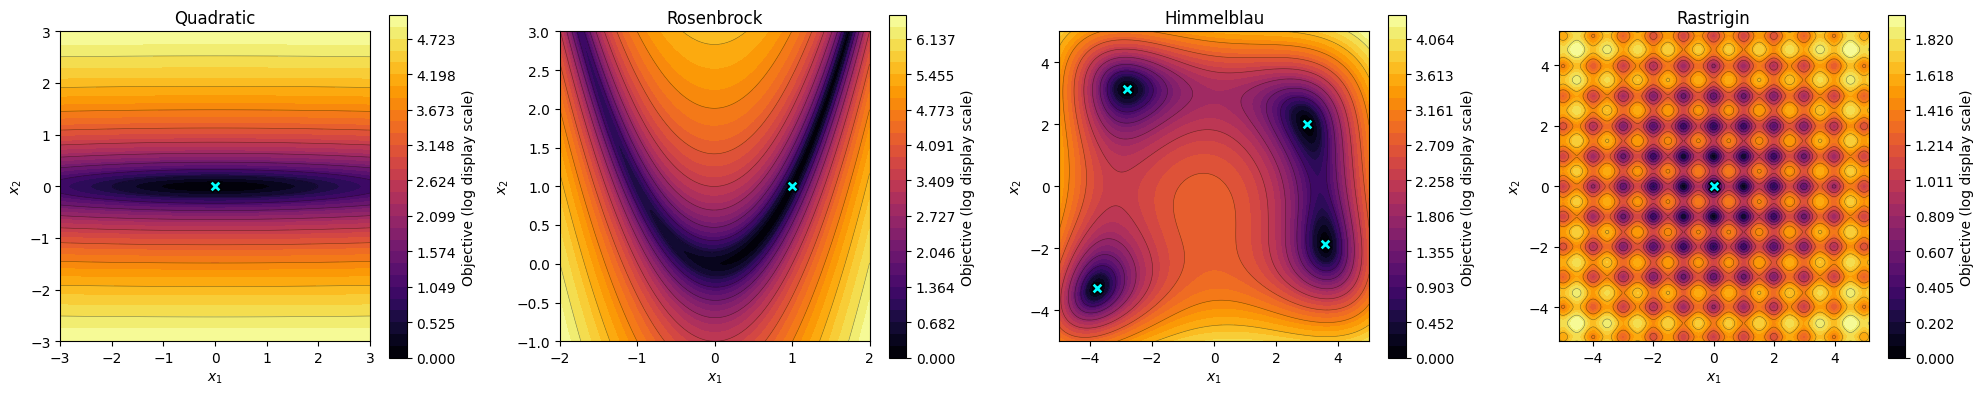

In [ ]:
fig, ax = plt.subplots(1,4,figsize=(20,4))

problems['quadratic'].plot_contours(ax=ax[0])
problems['rosenbrock'].plot_contours(ax=ax[1])
problems['himmelblau'].plot_contours(ax=ax[2])
problems['rastrigin'].plot_contours(ax=ax[3])

for axi in ax:
    axi.set_aspect('equal')
plt.tight_layout()
plt.show()

| Optimiser             | Order  | Information used                              | Search type | Deterministic? |
| --------------------- | ------ | --------------------------------------------- | ----------- | -------------- |
| Nelder–Mead           | Zeroth | $f(x)$ only                                   | Local       | Yes            |
| Gradient descent      | First  | $f(x)$, $\nabla f(x)$                         | Local       | Yes            |
| Momentum              | First  | $f(x)$, $\nabla f(x)$                         | Local       | Yes            |
| Adam                  | First  | $f(x)$, $\nabla f(x)$                         | Local       | Yes            |
| BFGS                  | First  | $f(x)$, $\nabla f(x)$                         | Local       | Yes            |
| Newton’s method       | Second | $f(x)$, $\nabla f(x)$, $\nabla^2 f(x)$        | Local       | Yes            |
| Random search         | Zeroth | $f(x)$ only                                   | Global      | No             |
| Simulated annealing   | Zeroth | $f(x)$ only                                   | Global      | No             |
| Bayesian optimisation | Zeroth | $f(x)$ only                                   | Global      | No             |

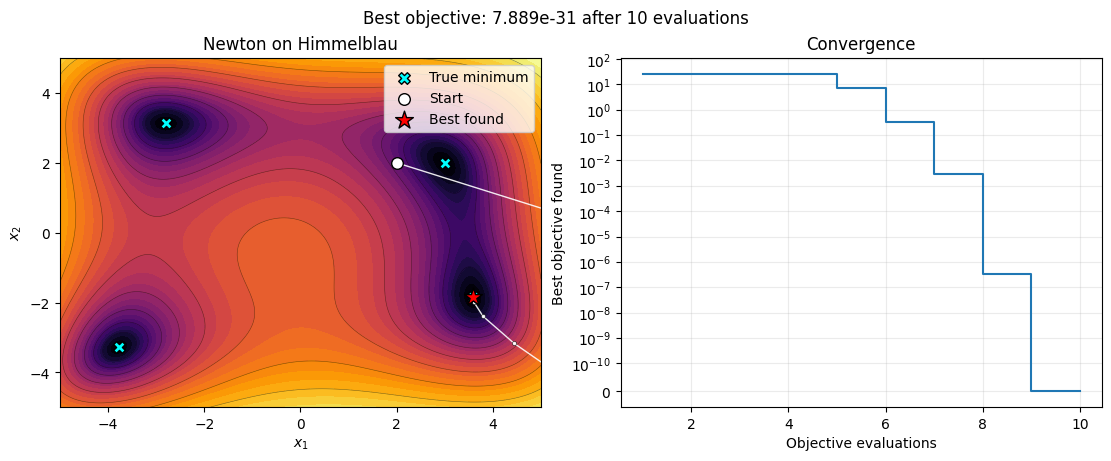

In [ ]:
# problem & optimiser
problem = problems['himmelblau']
optimiser = optimisers['newton']

# initial condition and evaluation budget
x0 = np.array([2.,2.])
MAX_EVALS = 100

# run & plot
result = optimiser.run(problem, x0, max_evals=MAX_EVALS)
plot_result(problem, result)
plt.show()

# **Predict which zeroth order method will perform best for each function.**
- Does this depend on the evaluation budget?
# **Predict which first order method will perform best for each function.**

# Who can get the best ```rosenbrock``` result after just 30 evaluations?

You can only use optimisers that use gradient information - no second order gradient information (i.e. Newton's method) - so pick from the following
- nelder_mead
- gradient_descent
- momentum
- adam
- bfgs
- random_search
- simulated_annealing
- bayesian_optimisation

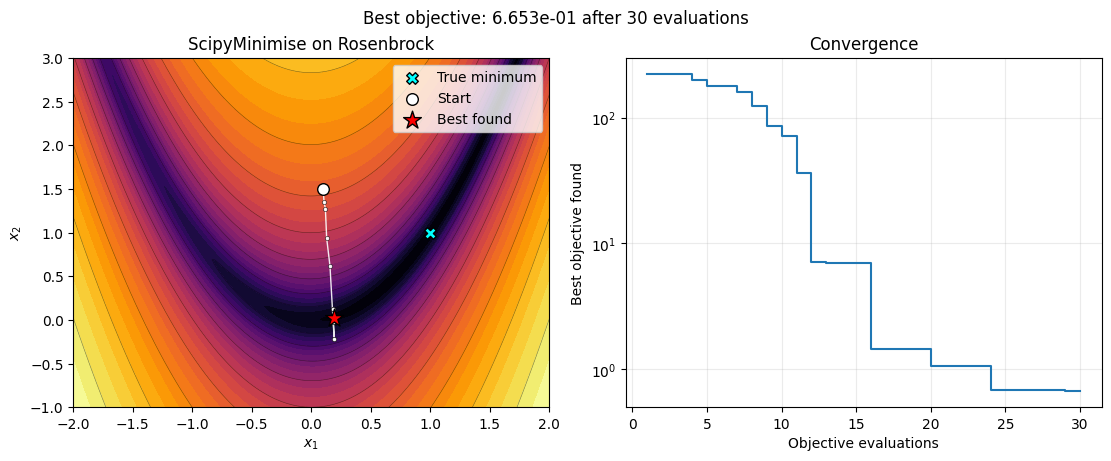

In [ ]:
problem = problems['rosenbrock']
MAX_EVALS = 30
x0 = np.array([0.1,1.5])

###--------------------------------- CHANGE THE OPTIMISER
optimiser = optimisers['nelder_mead']

### Plotting
result = optimiser.run(problem, x0, max_evals=MAX_EVALS)
plot_result(problem, result)
plt.show()

(<Figure size 3240x1320 with 36 Axes>,
 array([[<Axes: title={'center': 'Nelder Mead'}, xlabel='$x_1$', ylabel='Quadratic\n$x_2$'>,
         <Axes: title={'center': 'Gradient Descent'}, xlabel='$x_1$'>,
         <Axes: title={'center': 'Momentum'}, xlabel='$x_1$'>,
         <Axes: title={'center': 'Adam'}, xlabel='$x_1$'>,
         <Axes: title={'center': 'Bfgs'}, xlabel='$x_1$'>,
         <Axes: title={'center': 'Newton'}, xlabel='$x_1$'>,
         <Axes: title={'center': 'Random Search'}, xlabel='$x_1$'>,
         <Axes: title={'center': 'Simulated Annealing'}, xlabel='$x_1$'>,
         <Axes: title={'center': 'Bayesian Optimisation'}, xlabel='$x_1$'>],
        [<Axes: xlabel='$x_1$', ylabel='Rosenbrock\n$x_2$'>,
         <Axes: xlabel='$x_1$'>, <Axes: xlabel='$x_1$'>,
         <Axes: xlabel='$x_1$'>, <Axes: xlabel='$x_1$'>,
         <Axes: xlabel='$x_1$'>, <Axes: xlabel='$x_1$'>,
         <Axes: xlabel='$x_1$'>, <Axes: xlabel='$x_1$'>],
        [<Axes: xlabel='$x_1$', ylabel='Himmel

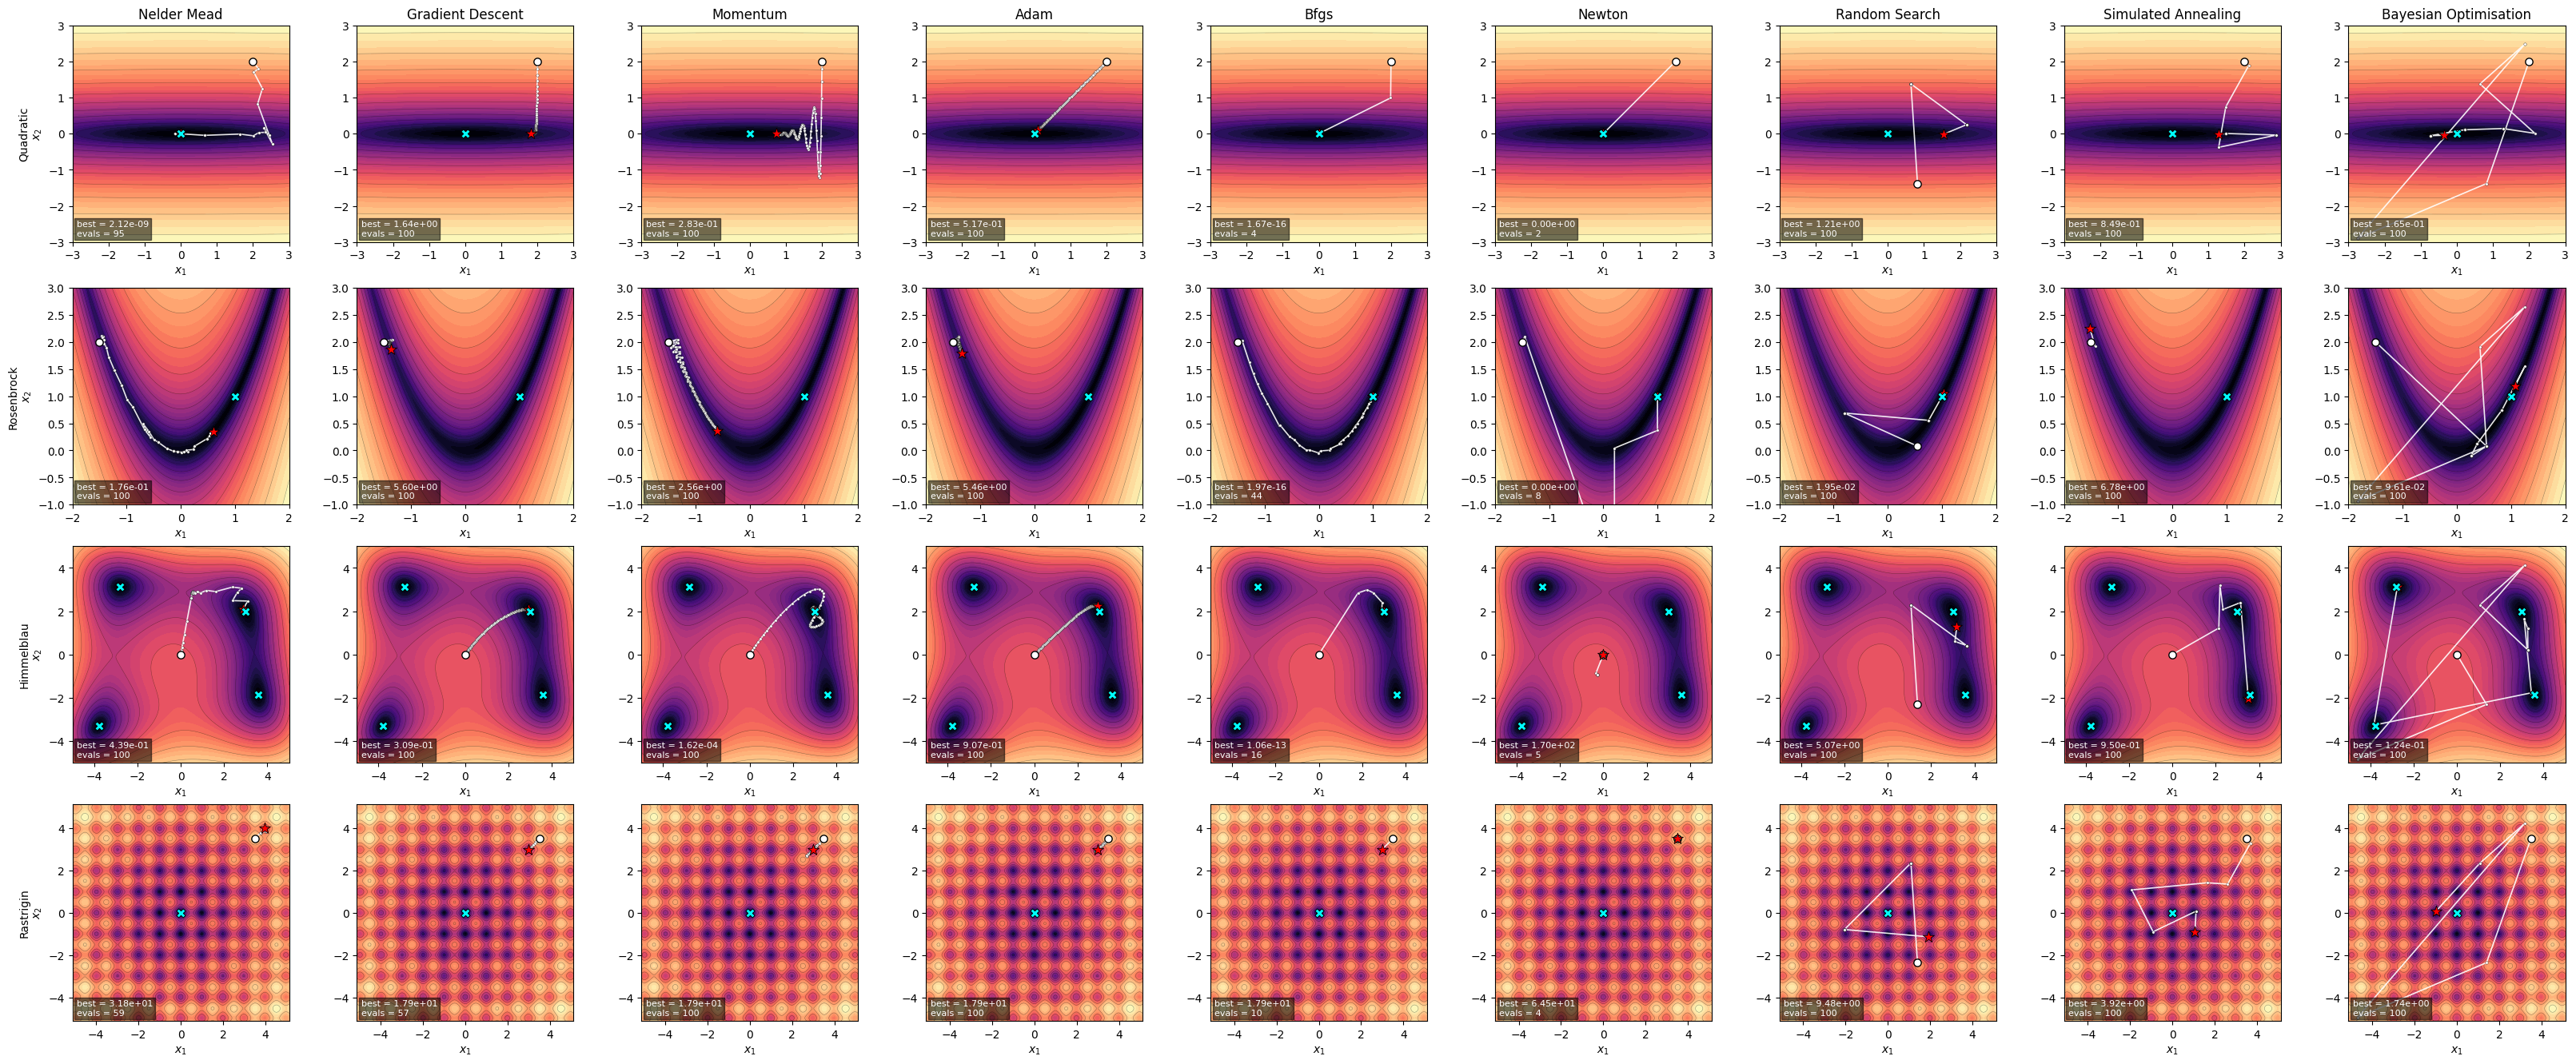

In [ ]:
plot_trajectory_matrix(problems, optimisers, max_evals=100)